### Instruction Fine tuning on GPT-2
- We have a model trained to predict the next token to generate a coherent sentence. How can we use this model  to actually follow instruction just like our chatbots now?
- There are two ways to fine tune LLMs
  - Supervised fine tuning for classfication purpose. Basically adds a classfication layer on top of the model network, unfreeze the parameters of last layers or just the classfication head and retrain the model to update the weights for that specific task.
  - Instructional fine tuning to follow human instructions: highly useful for chatbot applications and personal assistants. 

In [1]:
import json
import os
import urllib

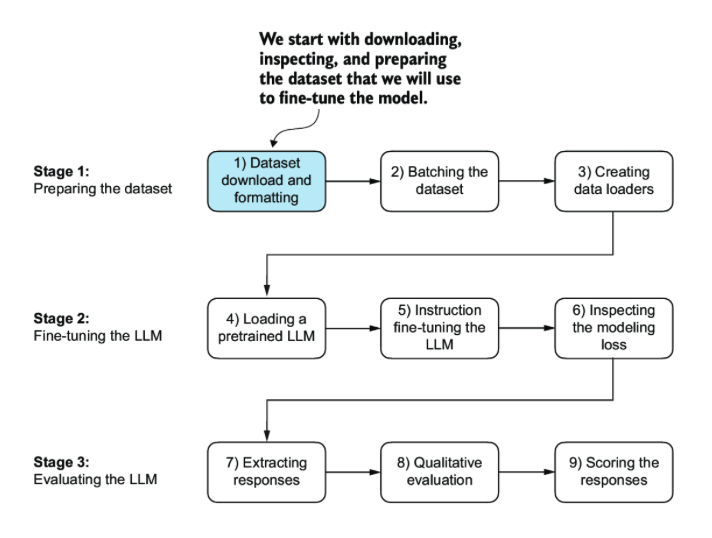

#### Dataset preparation for the fine tuning
Let's download a sample dataset and see how we can fine tune the LLM for instruction purpose.
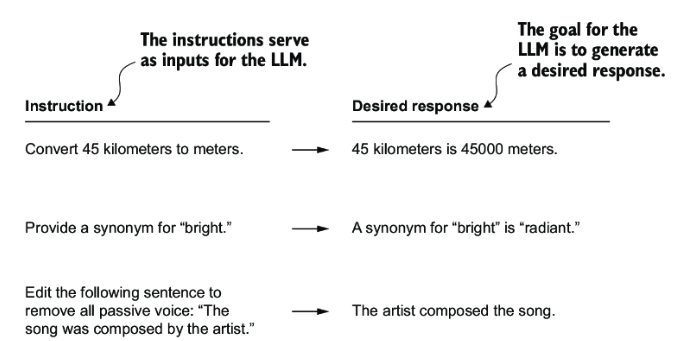

- Instruction fine-tuning involves training a model on dataset with just input and output pairs.
- There are different prompt styles for fine tuning:
  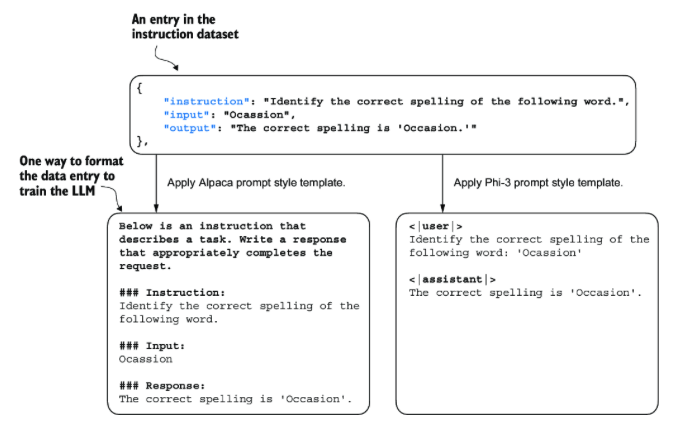

In [2]:
def download_and_load_file(file_path, url):
    if not os.path.exists(file_path):
        with urllib.request.urlopen(url) as response:
            text_data = response.read().decode("utf-8")
        with open(file_path, "w", encoding="utf-8") as file:
            file.write(text_data)
    
    with open(file_path, "r") as file:
        data = json.load(file)
    return data

file_path = "instruction-data.json"
url = (
    "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch"
    "/main/ch07/01_main-chapter-code/instruction-data.json"
)


data = download_and_load_file(file_path, url)
print("Number of entries:", len(data)) 

Number of entries: 1100


In [4]:
print("Example entry:\n", data[10])

Example entry:
 {'instruction': 'What is the contraction for "will not"?', 'input': '', 'output': 'The contraction for "will not" is "won\'t".'}


In [6]:
print("Example entry:\n", data[100])

Example entry:
 {'instruction': 'Name a synonym for "happiness."', 'input': '', 'output': 'A synonym for "happiness" is "joy."'}


In [7]:
# Prompt formatting function
def format_input(entry):
    instruction_text = (
        f"Below is an instruction that describes a task. "
        f"Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )

    input_text = (
        f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""
    )
    return instruction_text + input_text

In [10]:
print(data[50])

{'instruction': 'Identify the correct spelling of the following word.', 'input': 'Ocassion', 'output': "The correct spelling is 'Occasion.'"}


In [8]:
model_input = format_input(data[50])
desired_response = f"\n\n### Response:\n{data[50]['output']}"
print(model_input + desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Identify the correct spelling of the following word.

### Input:
Ocassion

### Response:
The correct spelling is 'Occasion.'


In [11]:
model_input = format_input(data[200])
desired_response = f"\n\n### Response:\n{data[200]['output']}"
print(model_input + desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
What is the chemical formula for ammonia?

### Response:
The chemical formula for ammonia is NH3.


#### Dataset partitioning

In [12]:
train_portion = int(len(data) * 0.85)    
test_portion = int(len(data) * 0.1)           
val_portion = len(data) - train_portion - test_portion   

train_data = data[:train_portion]
test_data = data[train_portion:train_portion + test_portion]
val_data = data[train_portion + test_portion:]

print("Training set length:", len(train_data))
print("Validation set length:", len(val_data))
print("Test set length:", len(test_data)) 

Training set length: 935
Validation set length: 55
Test set length: 110


#### Dataset Batching process
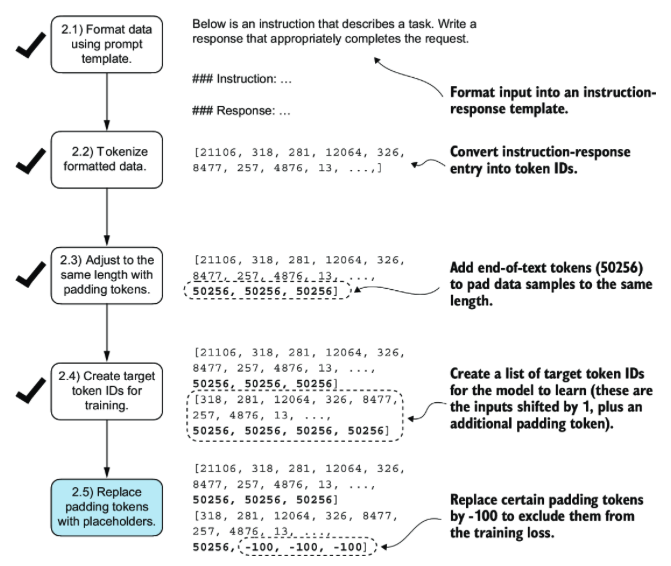
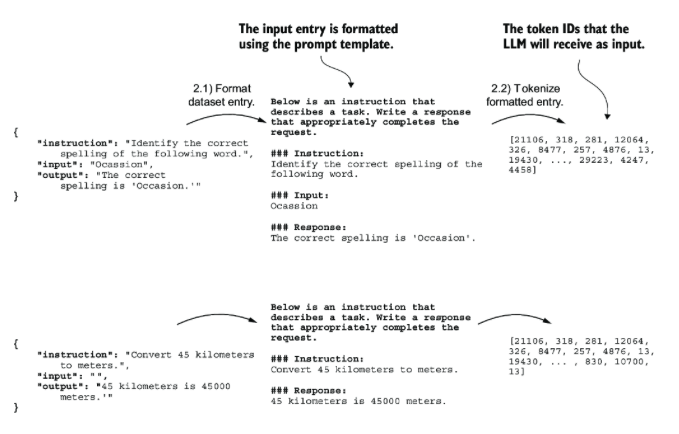

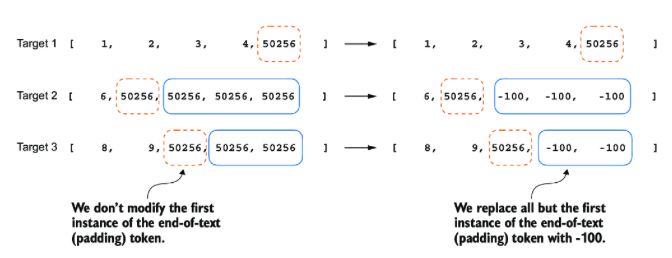

In [ ]:
#### Custom batch collate function
## Basically a function to modify the batch from Dataset class before feeding into the dataloader
def custom_collate_fn(
    batch,
    pad_token_id=50256,
    ignore_index=-100,
    allowed_max_length=None,
    device="cpu"
):
    batch_max_length = max(len(item)+1 for item in batch) # find the maximum length of text for padding other samples
    inputs_lst, targets_lst = [], []

    for item in batch:
        new_item = item.copy()
        new_item += [pad_token_id]  # adding an EOS token to each sample


        padded = (                               #1 Pad the sequences to the maximum length
            new_item + [pad_token_id] *          #1
            (batch_max_length - len(new_item))   #1
        )
        inputs = torch.tensor(padded[:-1])      #2
        targets = torch.tensor(padded[1:])     #3

        mask = targets == pad_token_id              #4
        indices = torch.nonzero(mask).squeeze()     #4
        if indices.numel() > 1:                     #4
            targets[indices[1:]] = ignore_index     #4

        if allowed_max_length is not None:
            inputs = inputs[:allowed_max_length]       #5
            targets = targets[:allowed_max_length]     #5

        inputs_lst.append(inputs)
        targets_lst.append(targets)

    inputs_tensor = torch.stack(inputs_lst).to(device)
    targets_tensor = torch.stack(targets_lst).to(device)
    return inputs_tensor, targets_tensor 